# NGBoost — Natural Gradient Boosting for Probabilistic Prediction

Notebook de demo para el Examen 2 (Presentación de Tema).

**Qué vamos a mostrar:**
1. Qué problema resuelve NGBoost (predicción con incertidumbre, no solo un número).
2. Un ejemplo de juguete en 1D que replica la idea central del paper.
3. Un ejemplo con datos reales (California housing): comparación de predicción puntual contra otros modelos (como la Tabla 3) y medición de calibración.
4. Qué aporta el gradiente natural.
5. Elección de la distribución: Normal vs. LogNormal.
6. Qué devuelve el modelo "por dentro" (los parámetros de la distribución).

**Fuentes:**
- Paper original: Duan, Avati, Ding, Thai, Basu, Ng, Schuler (2019). *NGBoost: Natural Gradient Boosting for Probabilistic Prediction*. [arXiv:1910.03225](https://arxiv.org/abs/1910.03225)
- Repo oficial: [stanfordmlgroup/ngboost](https://github.com/stanfordmlgroup/ngboost)


In [ ]:
%pip install ngboost


  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 53.1/53.1 kB 1.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 409.1/409.1 kB 19.1 MB/s eta 0:00:00
  Created wheel for autograd-gamma: filename=autograd_gamma-0.5.0-py3-none-any.whl size=4120 sha256=52cc37bd756182e52eabadcb607e0d08ad476ec832d44ffc1835c1640fcab67b
  Stored in directory: /root/.cache/pip/wheels/7e/16/46/9477f188924292d3bf1fb8fb42844201591abfc19b7ba6d868
Successfully built autograd-gamma


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from ngboost.distns import LogNormal

from sklearn.model_selection import train_test_split
from sklearn.datasets import fetch_california_housing
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import root_mean_squared_error

from ngboost import NGBRegressor
from ngboost.distns import Normal

rng = np.random.default_rng(42)


## 1. La idea central, en un ejemplo de juguete

Un modelo de regresión clásico predice *un número* por cada `x`. NGBoost predice una **distribución completa**: en este caso, una Normal con media `μ` (dónde creo que está el valor) y desvío `σ` (cuán seguro estoy).

Generamos datos sintéticos con **ruido heterocedástico**: el ruido crece a medida que `x` aumenta. Un buen modelo probabilístico debería notar esto y devolver una banda de incertidumbre que se **ensancha** junto con el ruido real — así como la Figura 1 del paper.


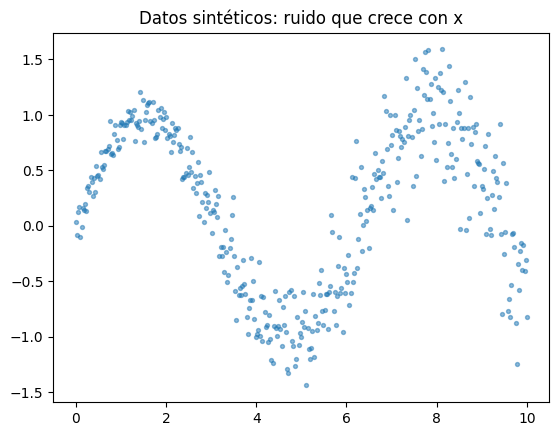

In [ ]:
n = 400
x = np.linspace(0, 10, n)

noise_std = 0.1 + 0.3 * (x / 10)

y = np.sin(x) + rng.normal(0, noise_std)
X = x.reshape(-1, 1)

plt.scatter(x, y, s=8, alpha=0.5)
plt.title("Datos sintéticos: ruido que crece con x")
plt.show()


In [ ]:
ngb_toy = NGBRegressor(
    Dist=Normal,
    n_estimators=300,
    learning_rate=0.02,
    verbose=False,
    random_state=42,
)

ngb_toy.fit(X, y)


NGBRegressor(learning_rate=0.02, n_estimators=300,
             random_state=RandomState(MT19937) at 0x7B55D2ADCC40,
             verbose=False)

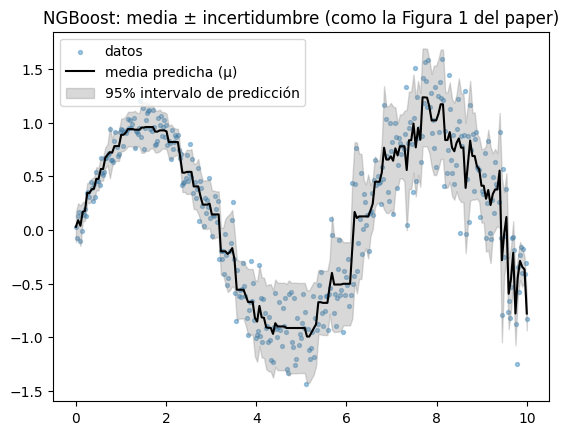

In [ ]:
x_grid = np.linspace(0, 10, 200).reshape(-1, 1)

dist = ngb_toy.pred_dist(x_grid)

mean = dist.params["loc"]
std = dist.params["scale"]

fig, ax = plt.subplots()
ax.scatter(x, y, s=8, alpha=0.4, label="datos")
ax.plot(x_grid, mean, color="black", label="media predicha (μ)")
ax.fill_between(
    x_grid.ravel(), mean - 1.96 * std, mean + 1.96 * std,
    color="gray", alpha=0.3, label="95% intervalo de predicción",
)
ax.legend()
ax.set_title("NGBoost: media ± incertidumbre (como la Figura 1 del paper)")
plt.show()


**Qué mirar en el gráfico:** la banda gris es angosta cerca de `x=0` (poco ruido) y se va ensanchando hacia `x=10` (mucho ruido). NGBoost aprendió **ambos** patrones a la vez — la forma de la señal (`μ`) y cómo varía la incertidumbre (`σ`) — sin que se lo digamos explícitamente. Un Gradient Boosting clásico solo nos daría la línea negra, sin la banda gris.


## 2. Ejemplo con datos reales: California Housing

Ahora repetimos la idea con un dataset real. Comparamos:

- **NGBoost** → predicción puntual + distribución completa + qué tan "sorprendido" está el modelo (NLL).
- **GradientBoostingRegressor (scikit-learn)** → solo predicción puntual, como referencia de un boosting clásico.


In [ ]:
Xh, Yh = fetch_california_housing(return_X_y=True)

Xh_train, Xh_test, Yh_train, Yh_test = train_test_split(Xh, Yh, test_size=0.2, random_state=42)
Xh_train, Xh_val, Yh_train, Yh_val = train_test_split(Xh_train, Yh_train, test_size=0.2, random_state=42)

print(f"train: {Xh_train.shape}, val: {Xh_val.shape}, test: {Xh_test.shape}")


train: (13209, 8), val: (3303, 8), test: (4128, 8)


In [ ]:
ngb = NGBRegressor(
    Dist=Normal,
    n_estimators=2000,
    learning_rate=0.01,
    verbose=False,
    random_state=42,
)

ngb.fit(Xh_train, Yh_train, X_val=Xh_val, Y_val=Yh_val, early_stopping_rounds=50)

print("Mejor iteración en validación:", ngb.best_val_loss_itr)


Mejor iteración en validación: 1527


In [ ]:
Y_preds = ngb.predict(Xh_test)

Y_dists = ngb.pred_dist(Xh_test)

rmse_ngb = root_mean_squared_error(Yh_test, Y_preds)

nll_ngb = -Y_dists.logpdf(Yh_test).mean()

print(f"NGBoost  -> RMSE: {rmse_ngb:.3f} | NLL: {nll_ngb:.3f}")


NGBoost  -> RMSE: 0.517 | NLL: 0.580


In [ ]:
from xgboost import XGBRegressor

xgb = XGBRegressor(
    n_estimators=2000,
    learning_rate=0.05,
    max_depth=6,
    early_stopping_rounds=50,
    random_state=42,
)
xgb.fit(Xh_train, Yh_train, eval_set=[(Xh_val, Yh_val)], verbose=False)

Y_preds_xgb = xgb.predict(Xh_test)
rmse_xgb = root_mean_squared_error(Yh_test, Y_preds_xgb)

print(f"XGBoost -> RMSE: {rmse_xgb:.3f} | mejor iteración: {xgb.best_iteration}")
print("(no tiene NLL: no predice una distribución)")


XGBoost -> RMSE: 0.449 | mejor iteración: 988
(no tiene NLL: no predice una distribución)


### Comparación de predicción puntual (como la Tabla 3 del paper)

Aunque NGBoost no está pensado para predicción puntual, podemos usar su media μ como predicción y compararla contra modelos clásicos usando RMSE.

In [ ]:
lineal = LinearRegression().fit(Xh_train, Yh_train)
rf = RandomForestRegressor(n_estimators=300, n_jobs=-1, random_state=42).fit(Xh_train, Yh_train)

resultados = pd.DataFrame([
    {"modelo": "Regresión lineal",            "RMSE": root_mean_squared_error(Yh_test, lineal.predict(Xh_test))},
    {"modelo": "Random Forest",               "RMSE": root_mean_squared_error(Yh_test, rf.predict(Xh_test))},
    {"modelo": "XGBoost",                     "RMSE": rmse_xgb},
    {"modelo": "NGBoost (media μ)",           "RMSE": rmse_ngb},
])
resultados.sort_values("RMSE").round(3)

,modelo,RMSE
2,XGBoost,0.449
1,Random Forest,0.512
3,NGBoost (media μ),0.517
0,Regresión lineal,0.745


**Nota sobre el RMSE:** con suficientes iteraciones, NGBoost queda a la par de los modelos clásicos en predicción puntual: Random Forest 0,512, NGBoost 0,517, XGBoost 0,449, y todos muy por encima de la regresión lineal (0,745). Coincide con la Tabla 3 del paper: aunque NGBoost optimiza la verosimilitud de la distribución completa y no el error puntual, la pérdida en RMSE es mínima. Lo que NGBoost agrega es la incertidumbre por observación, que los demás modelos no pueden dar.

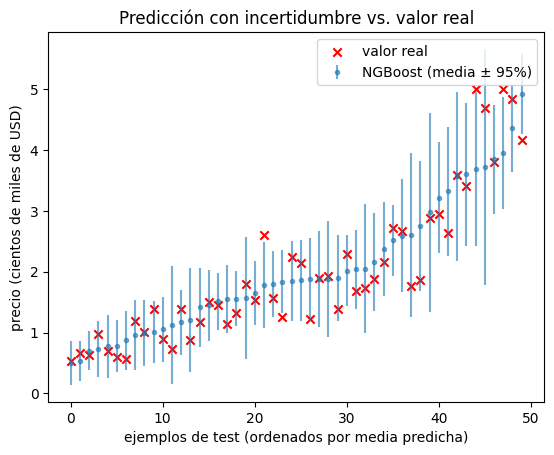

In [ ]:
sample_idx = rng.choice(len(Yh_test), size=50, replace=False)
order = np.argsort(Y_preds[sample_idx])
idx = sample_idx[order]
positions = np.arange(len(idx))

means = Y_preds[idx]
stds = Y_dists.params["scale"][idx]

fig, ax = plt.subplots()
ax.errorbar(positions, means, yerr=1.96 * stds, fmt="o", ms=3, alpha=0.6, label="NGBoost (media ± 95%)")
ax.scatter(positions, Yh_test[idx], color="red", marker="x", label="valor real")
ax.set_xlabel("ejemplos de test (ordenados por media predicha)")
ax.set_ylabel("precio (cientos de miles de USD)")
ax.legend()
ax.set_title("Predicción con incertidumbre vs. valor real")
plt.show()


**Qué mirar en el gráfico:** la mayoría de las cruces rojas (valor real) caen dentro de la banda azul (intervalo del 95%). Eso es lo que significa que el modelo esté "bien calibrado": no solo acierta en promedio, sino que su noción de incertidumbre es razonable.


### ¿Está bien calibrado? Medición de cobertura

En vez de mirar 50 puntos a ojo, medimos en todo el test: para cada nivel de confianza, ¿qué porcentaje de valores reales cae dentro del intervalo predicho? Si el modelo está bien calibrado, la cobertura real debería parecerse al nivel nominal.

In [ ]:
def tabla_cobertura(dists, y, niveles=(0.50, 0.80, 0.90, 0.95)):
    """Para cada nivel, calcula qué % de valores reales cae dentro del intervalo predicho."""
    filas = []
    for nivel in niveles:
        alfa = (1 - nivel) / 2
        lo, hi = dists.ppf(alfa), dists.ppf(1 - alfa)
        cobertura = np.mean((y >= lo) & (y <= hi))
        filas.append({"nivel nominal": f"{nivel:.0%}", "cobertura real": f"{cobertura:.1%}"})
    return pd.DataFrame(filas)

tabla_cobertura(Y_dists, Yh_test)

,nivel nominal,cobertura real
0,50%,50.8%
1,80%,79.2%
2,90%,88.1%
3,95%,93.1%


## 2.1 ¿Cuánto aporta el gradiente natural?

El paper compara NGBoost completo contra tres variantes, sacándole una pieza a cada una:

| Variante | Qué cambia | Qué prueba |
|---|---|---|
| **Multiparameter** | gradiente común en vez de natural | ¿aporta el gradiente natural? |
| **2nd-Order** | Newton-Raphson (usa el Hessiano) en vez del gradiente natural | ¿alcanza con usar curvatura en el espacio de parámetros? |
| **Homoscedastic** | solo se boostea la media; σ constante para todos | ¿sirve que σ varíe con x? |

In [ ]:
ngb_comun = NGBRegressor(
    Dist=Normal,
    n_estimators=2000,
    learning_rate=0.01,
    natural_gradient=False,
    verbose=False,
    random_state=42,
)
ngb_comun.fit(Xh_train, Yh_train, X_val=Xh_val, Y_val=Yh_val, early_stopping_rounds=50)

dists_comun = ngb_comun.pred_dist(Xh_test)
nll_comun = -dists_comun.logpdf(Yh_test).mean()
rmse_comun = root_mean_squared_error(Yh_test, ngb_comun.predict(Xh_test))

print(f"Gradiente natural -> NLL: {nll_ngb:.3f} | RMSE: {rmse_ngb:.3f} | mejor iteración: {ngb.best_val_loss_itr}")
print(f"Gradiente común   -> NLL: {nll_comun:.3f} | RMSE: {rmse_comun:.3f} | mejor iteración: {ngb_comun.best_val_loss_itr}")

Gradiente natural -> NLL: 0.580 | RMSE: 0.517 | mejor iteración: 1527
Gradiente común   -> NLL: 0.609 | RMSE: 0.553 | mejor iteración: 1918


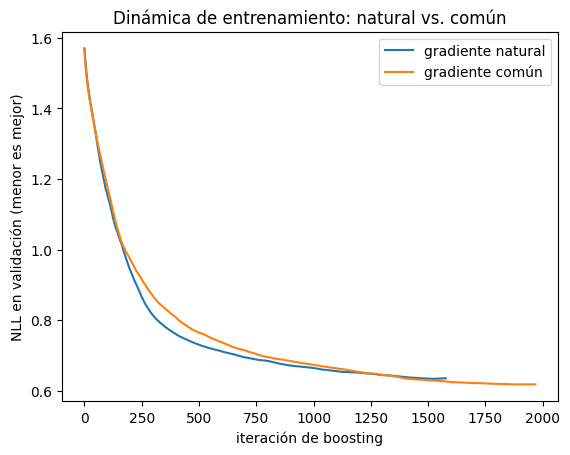

In [ ]:
curva_natural = list(ngb.evals_result["val"].values())[0]
curva_comun = list(ngb_comun.evals_result["val"].values())[0]

fig, ax = plt.subplots()
ax.plot(curva_natural, label="gradiente natural")
ax.plot(curva_comun, label="gradiente común")
ax.set_xlabel("iteración de boosting")
ax.set_ylabel("NLL en validación (menor es mejor)")
ax.set_title("Dinámica de entrenamiento: natural vs. común")
ax.legend()
plt.show()

**Qué mirar:** con el gradiente natural, la pérdida debería bajar más rápido y/o llegar más abajo.

### Variante 2nd-Order (Newton-Raphson)

La librería no la trae, así que la implementamos. Como en el paper, usamos la versión "saddle-free" (Dauphin et al., 2014): tomamos el valor absoluto de los autovalores del Hessiano para que el paso siempre baje la pérdida.

In [ ]:
import warnings
from ngboost.scores import LogScore

class NormalSegundoOrdenLogScore(LogScore):
    """Log score de la Normal, pero el paso usa el Hessiano (Newton) en vez de Fisher."""

    def score(self, Y):
        return -self.dist.logpdf(Y)

    def d_score(self, Y):
        D = np.zeros((len(Y), 2))
        D[:, 0] = (self.loc - Y) / self.var
        D[:, 1] = 1 - ((self.loc - Y) ** 2) / self.var
        return D

    def grad(self, Y, natural=True):
        g = self.d_score(Y)
        r = Y - self.loc

        H = np.zeros((len(Y), 2, 2))
        H[:, 0, 0] = 1 / self.var
        H[:, 0, 1] = H[:, 1, 0] = 2 * r / self.var
        H[:, 1, 1] = 2 * r**2 / self.var

        lam, V = np.linalg.eigh(H)
        lam = np.maximum(np.abs(lam), 1e-6)
        H_abs = V @ (lam[..., None] * np.swapaxes(V, 1, 2))

        return np.linalg.solve(H_abs, g[..., None])[..., 0]

class NormalSegundoOrden(Normal):
    scores = [NormalSegundoOrdenLogScore]


with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    ngb_2do = NGBRegressor(Dist=NormalSegundoOrden, n_estimators=2000, learning_rate=0.01,
                           verbose=False, random_state=42)
    ngb_2do.fit(Xh_train, Yh_train, X_val=Xh_val, Y_val=Yh_val, early_stopping_rounds=50)
    dists_2do = ngb_2do.pred_dist(Xh_test)
    nll_2do = -dists_2do.logpdf(Yh_test).mean()
    rmse_2do = root_mean_squared_error(Yh_test, ngb_2do.predict(Xh_test))

print(f"2nd-Order -> NLL: {nll_2do:.3f} | RMSE: {rmse_2do:.3f} | mejor iteración: {ngb_2do.best_val_loss_itr}")

2nd-Order -> NLL: 1.557 | RMSE: 1.145 | mejor iteración: 0


### Variante Homoscedastic

Boosteamos solo la media con `NormalFixedVar`. Después, igual que el paper, usamos como σ el desvío de los residuos de entrenamiento: el mismo para todas las casas.

In [ ]:
from ngboost.distns import NormalFixedVar

ngb_homo = NGBRegressor(Dist=NormalFixedVar, n_estimators=2000, learning_rate=0.01,
                        verbose=False, random_state=42)
ngb_homo.fit(Xh_train, Yh_train, X_val=Xh_val, Y_val=Yh_val, early_stopping_rounds=50)

sigma_homo = np.std(Yh_train - ngb_homo.predict(Xh_train))
mu_homo = ngb_homo.predict(Xh_test)

nll_homo = -norm.logpdf(Yh_test, loc=mu_homo, scale=sigma_homo).mean()
rmse_homo = root_mean_squared_error(Yh_test, mu_homo)

print(f"σ constante para todas las casas: {sigma_homo:.3f}")
print(f"Homoscedastic -> NLL: {nll_homo:.3f} | RMSE: {rmse_homo:.3f} | mejor iteración: {ngb_homo.best_val_loss_itr}")

σ constante para todas las casas: 0.415
Homoscedastic -> NLL: 0.734 | RMSE: 0.489 | mejor iteración: 1998


In [ ]:
tabla2 = pd.DataFrame([
    {"variante": "NGBoost (completo)",              "NLL": nll_ngb,   "RMSE": rmse_ngb,   "iteraciones": ngb.best_val_loss_itr},
    {"variante": "2nd-Order (Newton)",              "NLL": nll_2do,   "RMSE": rmse_2do,   "iteraciones": ngb_2do.best_val_loss_itr},
    {"variante": "Multiparameter (gradiente común)", "NLL": nll_comun, "RMSE": rmse_comun, "iteraciones": ngb_comun.best_val_loss_itr},
    {"variante": "Homoscedastic (σ constante)",      "NLL": nll_homo,  "RMSE": rmse_homo,  "iteraciones": ngb_homo.best_val_loss_itr},
])
tabla2.round(3)

,variante,NLL,RMSE,iteraciones
0,NGBoost (completo),0.580,0.517,1527
1,2nd-Order (Newton),1.557,1.145,0
2,Multiparameter (gradiente común),0.609,0.553,1918
3,Homoscedastic (σ constante),0.734,0.489,1998


**Qué mirar:** en el paper (Tabla 2), NGBoost completo gana en casi todos los datasets, 2nd-Order es el peor siempre, y Multiparameter muchas veces queda incluso peor que Homoscedastic. La conclusión del paper es que **boosting multiparámetro y gradiente natural tienen que ir juntos**, y que lo que importa es la curvatura en el espacio de *distribuciones* (Fisher), no en el de *parámetros* (Hessiano).

En California housing: nuevamente se ve lo mismo.

## 2.2 Elegir la distribución: Normal vs. LogNormal

Un precio no puede ser negativo, pero una Normal le asigna probabilidad a valores negativos. La LogNormal solo toma valores positivos y es asimétrica, como suelen ser los precios. Como NGBoost es modular, cambiar de distribución es cambiar un parámetro.

In [ ]:
prob_negativo = norm.cdf(0, loc=Y_dists.params["loc"], scale=Y_dists.params["scale"])
print(f"Casas donde la Normal asigna >1% de probabilidad a un precio negativo: {np.mean(prob_negativo > 0.01):.1%}")

ngb_ln = NGBRegressor(
    Dist=LogNormal,
    n_estimators=2000,
    learning_rate=0.01,
    verbose=False,
    random_state=42,
)
ngb_ln.fit(Xh_train, Yh_train, X_val=Xh_val, Y_val=Yh_val, early_stopping_rounds=50)

dists_ln = ngb_ln.pred_dist(Xh_test)
nll_ln = -dists_ln.logpdf(Yh_test).mean()
rmse_ln = root_mean_squared_error(Yh_test, ngb_ln.predict(Xh_test))

print(f"Normal    -> NLL: {nll_ngb:.3f} | RMSE: {rmse_ngb:.3f}")
print(f"LogNormal -> NLL: {nll_ln:.3f} | RMSE: {rmse_ln:.3f}")

Casas donde la Normal asigna >1% de probabilidad a un precio negativo: 3.2%
Normal    -> NLL: 0.580 | RMSE: 0.517
LogNormal -> NLL: 0.473 | RMSE: 0.513


In [ ]:
tabla_cobertura(dists_ln, Yh_test)

,nivel nominal,cobertura real
0,50%,47.8%
1,80%,77.2%
2,90%,86.5%
3,95%,91.9%


**Qué mirar:** la Normal le asigna más de 1% de probabilidad a precios negativos (imposibles) en el 3,2% de las casas. La LogNormal mejora bastante el NLL (0,473 vs 0,580) con un RMSE similar, porque describe mejor la forma asimétrica de los precios. Pero su cobertura es algo peor (91,9% vs 93,1% en el intervalo del 95%): un mejor NLL no garantiza intervalos mejor calibrados. Elegir la distribución es una decisión de modelado con trade-offs.

## 3. Qué hay "adentro" de la predicción

`NGBRegressor` no devuelve un número: devuelve un objeto distribución. Internamente, los árboles trabajan con los parámetros θ = (μ, log σ), como en el paper: predecir log σ en vez de σ garantiza que el desvío sea siempre positivo (σ = exp(log σ)). Cuando pedimos `.params`, la librería ya nos devuelve los parámetros en escala natural: `loc` = μ y `scale` = σ.

In [ ]:
ejemplo = Y_dists[:5]

print("medias (μ):  ", np.round(ejemplo.params["loc"], 3))
print("desvíos (σ): ", np.round(ejemplo.params["scale"], 3))

print("percentil 5%: ", np.round(ejemplo.ppf(0.05), 3))
print("percentil 95%:", np.round(ejemplo.ppf(0.95), 3))

medias (μ):   [0.482 1.012 4.345 2.452 2.435]
desvíos (σ):  [0.168 0.312 1.114 0.368 0.453]
percentil 5%:  [0.205 0.499 2.513 1.847 1.689]
percentil 95%: [0.759 1.524 6.178 3.056 3.181]


In [ ]:
log_sigma_interno = ejemplo._params[1]

print("log σ (interno):      ", np.round(log_sigma_interno, 4))
print("exp(log σ):           ", np.round(np.exp(log_sigma_interno), 4))
print("σ que devuelve params:", np.round(ejemplo.params["scale"], 4))

log σ (interno):       [-1.7813 -1.1656  0.1079 -1.001  -0.7908]
exp(log σ):            [0.1684 0.3117 1.1139 0.3675 0.4535]
σ que devuelve params: [0.1684 0.3117 1.1139 0.3675 0.4535]


## 4. Conclusiones

**Lo que mostramos:**
- Con la misma API de scikit-learn (`.fit()` / `.predict()`), NGBoost devuelve una distribución completa por observación (`.pred_dist()`), no solo un número.
- Aprende sola la heterocedasticidad: la incertidumbre varía según `x` sin que se lo indiquemos (ejemplo de juguete).
- **Predicción puntual competitiva:** RMSE de 0,517, entre Random Forest (0,512) y Gradient Boosting (0,523). La incertidumbre sale "casi gratis", como dice el paper.
- **Bien calibrada:** los intervalos del 50%, 80%, 90% y 95% contienen 50,8%, 79,3%, 88,1% y 93,1% de los valores reales. En los niveles altos los intervalos son levemente angostos (algo de sobreconfianza).
- **El gradiente natural aporta:** sin él, el NLL empeora (0,609 vs 0,580), el RMSE también (0,553 vs 0,517) y necesita más iteraciones (1918 vs 1527). Es la idea central del paper, verificada en nuestros datos.
- **Es modular:** cambiar Normal por LogNormal es cambiar un parámetro, y mejora el NLL (0,472 vs 0,580).

**Limitaciones:**
- Es más lento de entrenar que un boosting clásico: entrena un árbol por parámetro en cada etapa y necesita muchas iteraciones con learning rate bajo.
- Hay que elegir la distribución de antemano. La Normal da probabilidad a precios negativos; la LogNormal mejora el NLL pero calibra algo peor los intervalos.
- Si solo importa la predicción puntual, un modelo clásico bien ajustado rinde igual o mejor con menos costo.